# AIDA 2154 Final Project – 04 Transfer Learning Compared with the Baseline

**Data version 2** (`shared/synthetic-data/kit-cards/`), using notebook 02's frozen regions and notebook 03's baseline results.

**Question:** Does a small pretrained neural network, trained using the same frozen regions, classify regions and flag missing items better than notebook 03's colour-and-shape baseline? Is any gain worth the added complexity?

**Method in brief.** Both classifiers use **the same frozen regions** from notebook 02's segmentation; they differ in what they see. The baseline uses colour and shape features from each region's predicted foreground mask; here, each region is cropped from its card and classified by **MobileNetV3-Small**, a small convolutional neural network pretrained on ImageNet. Only its last feature block and its classifier head, whose final layer is replaced with a new six-class output (the five kit items and "not a kit item"), are trained, with light augmentation, on the same 916 training regions the baseline used. Training settings and the stopping point are chosen on an internal hold-out of **training cards**; validation is not used for tuning. The network's region predictions then go through **the same card decision rule** as the baseline, and both are compared on validation with the measures fixed in notebook 03.

**What counts as a card-level error.** A validation card has an error if any of its item decisions is a false missing-item flag, a missed omission or an unexpected detection. Decisions for items whose expectation is unknown are not scored.

**Decision rule, fixed before any network result is seen.** The baseline goes forward to robustness testing and the single test evaluation **unless the network makes strictly fewer card-level errors on validation and is no worse on every main measure**: missing-item recall, missing-item precision, false missing-item flags, unexpected detections and completely correct cards. The baseline made one card-level error (an unexpected detection on 1 of 118 cards with all expectations known), so the network would have to get every card right, keep all 43 omissions flagged, and make no false flags or unexpected detections. Validation is used once, to make this choice.

Everything uses training and validation cards only; no test image is opened, and the test set stays untouched until the method is frozen. All cards are computer-generated, so the results describe these cards, not real kits.

In [1]:
import hashlib
import json
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from PIL import Image
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
KIT = SD / "kit-cards"
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(exist_ok=True)
ITEMS = ["access_badge", "safety_vest", "hard_hat", "laptop", "phone"]
NOT_KIT = "not_kit_item"
CLASSES = ITEMS + [NOT_KIT]
DEV_SPLITS = ["train", "validation"]                  # only development images are opened

# Seeds, recorded separately for each random step
SEEDS = {"internal_holdout_split": 2026, "augmentation": 2027, "training": 2028}

sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
manifest = pd.read_csv(KIT / "manifest.csv", keep_default_na=False, na_values=[""])
regions = pd.read_csv(OUTPUT_DIR / "regions_dev.csv", keep_default_na=False, na_values=[""])                  # notebook 02
baseline_pred = pd.read_csv(OUTPUT_DIR / "region_predictions_dev.csv", keep_default_na=False, na_values=[""])  # notebook 03
training_regions = pd.read_csv(OUTPUT_DIR / "classifier_training_regions.csv")                                 # notebook 03
baseline_settings = json.loads((OUTPUT_DIR / "classifier_settings.json").read_text())

# The regions and training rows must be the ones the baseline was built from
assert sha(OUTPUT_DIR / "regions_dev.csv") == baseline_settings["regions_dev_sha256"], "Regions differ from notebook 03's"
assert sha(OUTPUT_DIR / "classifier_training_regions.csv") == baseline_settings["training_regions_sha256"], \
    "Training regions differ from notebook 03's"
assert len(training_regions) == baseline_settings["training_regions"] == 916
key = ["card_id", "region"]
assert baseline_pred[key].equals(regions[key]) and set(regions["split"]) == set(DEV_SPLITS), \
    "Baseline predictions must cover exactly the saved development regions, in order"

# Pretrained weights: the cached file must be the expected one
WEIGHTS = MobileNet_V3_Small_Weights.IMAGENET1K_V1
weights_file = Path(torch.hub.get_dir()) / "checkpoints" / Path(WEIGHTS.url).name
WEIGHTS_SHA256 = "047dcff4addef86ea5bc2eff13c9614dc11f47ab1160d0a71a25e7db994f4e1f"
assert weights_file.exists(), f"Pretrained weights not found at {weights_file}; see the README for the download step"
assert sha(weights_file) == WEIGHTS_SHA256, "The cached pretrained weights are not the expected file"

# CPU only, deterministic algorithms, fixed thread count, so reruns in the same software and hardware environment give the same numbers
torch.use_deterministic_algorithms(True)
torch.set_num_threads(4)
DEVICE = torch.device("cpu")
versions = {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "pillow": Image.__version__}
print(f"Data version {DATA_VERSION}; {len(regions):,} development regions "
      f"({regions['split'].value_counts().to_dict()}); 916 training regions from notebook 03")
print(f"Pretrained weights: {weights_file.name} (sha256 checked); device: CPU, {torch.get_num_threads()} threads")
print("Versions:", versions)
print("Seeds:", SEEDS)

Data version 2; 1,243 development regions ({'train': 921, 'validation': 322}); 916 training regions from notebook 03
Pretrained weights: mobilenet_v3_small-047dcff4.pth (sha256 checked); device: CPU, 4 threads
Versions: {'python': '3.14.7', 'torch': '2.15.0', 'torchvision': '0.29.2', 'numpy': '2.5.3', 'pandas': '3.0.6', 'pillow': '12.3.0'}
Seeds: {'internal_holdout_split': 2026, 'augmentation': 2027, 'training': 2028}


## A. Region crops

Each region is cut from its card image as a **square window** centred on the region's box: the side is the longer box side plus a 6-pixel margin on each side, so the item's shape is not stretched. Where the window runs past the card edge, the edge pixels are repeated. Each crop is resized to 224 × 224 pixels and normalised with ImageNet's channel means and standard deviations, as the pretrained network expects.

The crops come from the **original card image**, not from notebook 03's predicted foreground mask, so the network sees the item, a little surrounding paper and any noise or blur, as a person would. Only training and validation cards are opened.

**Reference labels** are notebook 03's: a kit-item region is labelled with its item, and a background or unmatched region as "not a kit item". Validation regions without a single reference keep a blank label and still pass through the card decisions.

**Internal hold-out.** About 20% of the **training cards** (seed 2026) are held out, before any crop is augmented, to choose training settings and the stopping point. Every crop from a card stays on the same side, and both sides must contain all six classes, or the notebook stops. Validation is not part of this split.

part,internal_fit,internal_holdout,all_training
reference,,,
access_badge,147,41,188
safety_vest,139,38,177
hard_hat,136,39,175
laptop,71,17,88
phone,73,15,88
not_kit_item,165,35,200
cards,275,69,344


Crops: 1,243 regions at 224 x 224; unused training-card regions (not in notebook 03's training rule): 5


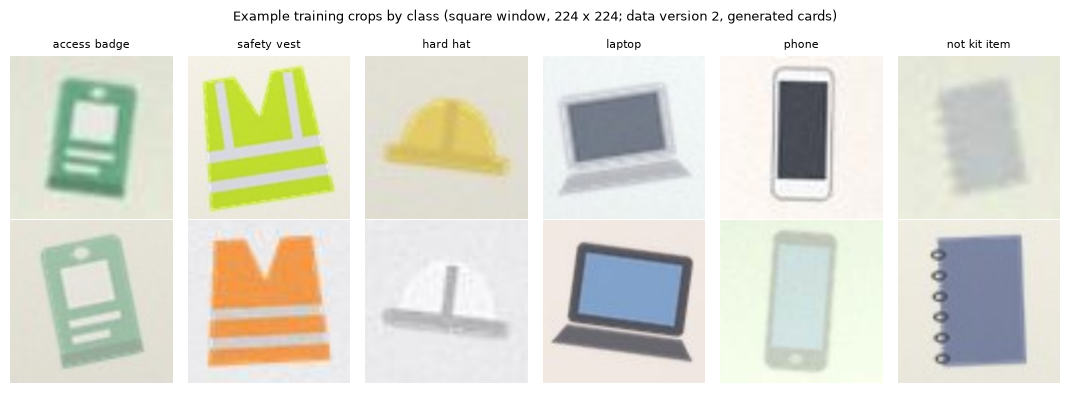

In [2]:
CROP_SIZE, MARGIN = 224, 6
files = manifest.set_index("card_id")["file_name"]
assert set(manifest.loc[manifest["card_id"].isin(regions["card_id"]), "split"]) <= set(DEV_SPLITS)


def square_crop(image, x0, y0, x1, y1):
    # Square window around the box (longer side + margin); edge pixels repeated past the card border
    side = max(x1 - x0, y1 - y0) + 2 * MARGIN                   # one integer side, so the window is always square
    left = (x0 + x1 - side) // 2
    top = (y0 + y1 - side) // 2
    right, bottom = left + side, top + side
    h, w = image.shape[:2]
    pad = max(0, -left, -top, right - w, bottom - h)
    padded = np.pad(image, ((pad, pad), (pad, pad), (0, 0)), mode="edge")
    crop = padded[top + pad:bottom + pad, left + pad:right + pad]
    assert crop.shape[:2] == (side, side), "The crop window is not square"
    return crop


# Built in saved region-row order, so crop k always belongs to row k of the regions table
# Only the current card's image is kept in memory; a card is reopened only if its rows are not together
crops = np.zeros((len(regions), CROP_SIZE, CROP_SIZE, 3), dtype=np.uint8)
current_card, image = None, None
for k, r in enumerate(regions.itertuples()):
    if r.card_id != current_card:
        current_card, image = r.card_id, np.asarray(Image.open(KIT / "images" / files[r.card_id]).convert("RGB"))
    crop = square_crop(image, r.x0, r.y0, r.x1, r.y1)
    crops[k] = np.asarray(Image.fromarray(crop).resize((CROP_SIZE, CROP_SIZE), Image.Resampling.BILINEAR))
del image

data = regions[["card_id", "split", "region", "label_group"]].copy()
data["reference"] = baseline_pred["reference"].to_numpy()
data["baseline"] = baseline_pred["predicted"].to_numpy()
train_keys = set(map(tuple, training_regions[key].to_numpy()))
data["training_region"] = [k in train_keys for k in map(tuple, data[key].to_numpy())]
assert int(data["training_region"].sum()) == 916 and (data.loc[data["training_region"], "split"] == "train").all()
labelled = data.loc[data["training_region"]].merge(training_regions, on=key, suffixes=("", "_03"))
assert (labelled["reference"] == labelled["reference_03"]).all(), "Training labels differ from notebook 03's"

# Internal hold-out: about 20% of training cards, split by card before any augmentation
train_cards = np.array(sorted(data.loc[data["training_region"], "card_id"].unique()))
rng = np.random.default_rng(SEEDS["internal_holdout_split"])
holdout_cards = set(rng.choice(train_cards, size=round(0.2 * len(train_cards)), replace=False))
data["part"] = np.select([data["training_region"] & data["card_id"].isin(holdout_cards), data["training_region"],
                          data["split"] == "validation"], ["internal_holdout", "internal_fit", "validation"], default="unused")
parts = data[data["part"].isin(["internal_fit", "internal_holdout"])]
assert set(parts.loc[parts["part"] == "internal_fit", "card_id"]).isdisjoint(parts.loc[parts["part"] == "internal_holdout", "card_id"])
for p in ["internal_fit", "internal_holdout"]:
    assert set(parts.loc[parts["part"] == p, "reference"]) == set(CLASSES), f"The {p} part is missing a class"

split_table = (pd.crosstab(parts["reference"], parts["part"]).reindex(CLASSES)
               .assign(all_training=lambda t: t.sum(axis=1)))
split_table.loc["cards"] = [parts.loc[parts["part"] == c, "card_id"].nunique() for c in ["internal_fit", "internal_holdout"]] \
    + [len(train_cards)]
split_table.insert(0, "data_version", DATA_VERSION)
split_table.to_csv(OUTPUT_DIR / "tl_internal_split.csv")
display(split_table.drop(columns="data_version"))
print(f"Crops: {crops.shape[0]:,} regions at {CROP_SIZE} x {CROP_SIZE}; "
      f"unused training-card regions (not in notebook 03's training rule): {int((data['part'] == 'unused').sum())}")

# Example crops: the first two training crops of each class, in saved order
fig, axes = plt.subplots(2, len(CLASSES), figsize=(1.8 * len(CLASSES), 4))
for j, cls in enumerate(CLASSES):
    idx = data.index[data["training_region"] & (data["reference"] == cls)][:2]
    for i, k in enumerate(idx):
        axes[i, j].imshow(crops[k])
        axes[i, j].axis("off")
    axes[0, j].set_title(cls.replace("_", " "), fontsize=8)
fig.suptitle("Example training crops by class (square window, 224 x 224; data version 2, generated cards)", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "tl_example_crops.png", dpi=120, bbox_inches="tight")
plt.show()

## B. Training, with settings chosen on training cards

**Network.** MobileNetV3-Small with its ImageNet weights. Its 13 feature blocks are kept fixed except the **last block**, and the pretrained classifier head is kept with a **new final layer** of six outputs. Only the last block and the head are trained (about 0.65 million of the network's 1.5 million weights after the change). The fixed blocks also keep their batch-normalisation statistics from ImageNet.

**Training.** Cross-entropy loss with **balanced class weights** (each class's weight is inversely proportional to its number of training regions, as in the baseline), the AdamW optimiser and batches of 32 crops. Each training round (epoch) shows every training crop once, in an order shuffled with the training seed (2028).

**Augmentation** (training crops only, applied as each batch is built, with its own seed, 2027): a random square sub-window covering 85–100% of the crop, resized back to 224 × 224, and brightness and contrast each scaled by a random factor between 0.8 and 1.2. The generator already varies rotation, size, contrast and blur, so augmentation is kept light. Held-out and validation crops are never augmented.

**Choosing settings.** Two learning rates (0.001 and 0.0003) are each trained for up to 10 epochs on the internal-fit cards, and after every epoch the model is scored on the regions of the 69 held-out training cards with **region macro F1** over the six classes, the same region-level selection measure as the baseline. It measures crop classification, not card decisions. The learning rate and epoch count with the highest hold-out region macro F1 are chosen; ties go to fewer epochs, then the lower learning rate.

**Final model.** A fresh network is then trained on **all 916 training regions** with the chosen learning rate and number of epochs, so both classifiers learn from exactly the same examples. Only after that is validation scored (section C). The trained layers, including the last block's batch-normalisation statistics, are saved (`tl_trained_layers.pt`). Before section C, a fresh network is rebuilt from the checked pretrained weights and that file, and its predictions on the held-out training regions must match the trained model's exactly, so the saved file is confirmed to hold everything needed for later evaluation.

Settings search: 353 s


,learning_rate,epoch,training_loss,holdout_macro_f1,holdout_accuracy
0,0.0010,1,0.2944,0.9847,0.9892
1,0.0010,2,0.0074,1.0000,1.0000
2,0.0010,3,0.0027,1.0000,1.0000
3,0.0010,4,0.0014,1.0000,1.0000
4,0.0010,5,0.0012,1.0000,1.0000
5,0.0010,6,0.0027,1.0000,1.0000
6,0.0010,7,0.0009,1.0000,1.0000
7,0.0010,8,0.0010,1.0000,1.0000
8,0.0010,9,0.0008,1.0000,1.0000
9,0.0010,10,0.0004,1.0000,1.0000


Chosen on the internal hold-out: learning rate 0.0003, 2 epochs (hold-out region macro F1 1.000)
Final model trained on 916 regions in 38 s; saved 10 trained tensors (2.6 MB)
Rebuilt model from the pretrained weights and the saved layers: predictions on the held-out regions match exactly


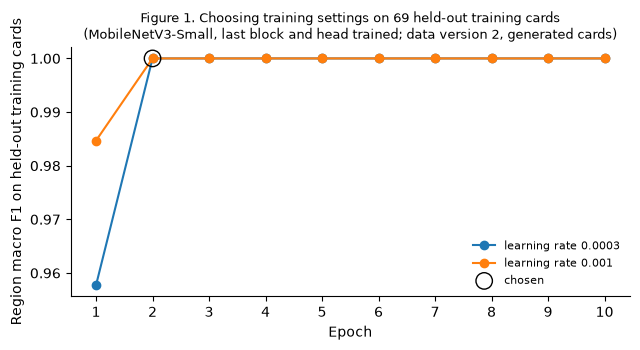

In [3]:
from sklearn.metrics import f1_score
import torchvision.transforms.v2.functional as TF

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)      # ImageNet channel statistics
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
CLASS_INDEX = {c: i for i, c in enumerate(CLASSES)}
LR_GRID, MAX_EPOCHS, BATCH = [1e-3, 3e-4], 10, 32
all_images = torch.from_numpy(crops).permute(0, 3, 1, 2)         # uint8, N x 3 x 224 x 224


def build_model():
    model = mobilenet_v3_small(weights=WEIGHTS)                   # loads the checked cached file
    model.classifier[3] = torch.nn.Linear(model.classifier[3].in_features, len(CLASSES))
    for p in model.parameters():
        p.requires_grad = False
    for p in list(model.features[-1].parameters()) + list(model.classifier.parameters()):
        p.requires_grad = True
    return model.to(DEVICE)


def set_train_mode(model):
    model.train()
    model.features[:-1].eval()                                   # fixed blocks keep their ImageNet statistics


def augment(batch, gen):
    # Random square sub-window (85-100% of the side) resized back, then brightness and contrast factors in 0.8-1.2
    out = []
    for img in batch:
        side = int(round(CROP_SIZE * (0.85 + 0.15 * torch.rand(1, generator=gen).item())))
        top = int(torch.randint(0, CROP_SIZE - side + 1, (1,), generator=gen))
        left = int(torch.randint(0, CROP_SIZE - side + 1, (1,), generator=gen))
        img = TF.resized_crop(img, top, left, side, side, [CROP_SIZE, CROP_SIZE], antialias=True)
        img = TF.adjust_brightness(img, 0.8 + 0.4 * torch.rand(1, generator=gen).item())
        img = TF.adjust_contrast(img, 0.8 + 0.4 * torch.rand(1, generator=gen).item())
        out.append(img)
    return torch.stack(out)


def to_input(batch_uint8):
    return ((batch_uint8.float() / 255) - MEAN) / STD


@torch.no_grad()
def predict(model, idx):
    model.eval()
    probs = [torch.softmax(model(to_input(all_images[idx[i:i + 128]])), dim=1) for i in range(0, len(idx), 128)]
    return torch.cat(probs).numpy()


def train(idx_fit, labels_fit, lr, epochs, idx_eval=None, labels_eval=None):
    # Trains a fresh model; if evaluation rows are given, scores them after every epoch
    torch.manual_seed(SEEDS["training"])                         # same start (new layer, dropout) for every run
    order_gen = torch.Generator().manual_seed(SEEDS["training"])
    aug_gen = torch.Generator().manual_seed(SEEDS["augmentation"])
    model = build_model()
    counts = np.bincount(labels_fit, minlength=len(CLASSES))
    weights = torch.tensor(len(labels_fit) / (len(CLASSES) * counts), dtype=torch.float32)
    loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
    optimiser = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    y_fit = torch.from_numpy(labels_fit.copy())
    history = []
    for epoch in range(1, epochs + 1):
        set_train_mode(model)
        perm = torch.randperm(len(idx_fit), generator=order_gen).numpy()
        total = 0.0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            x = to_input(augment(all_images[idx_fit[b]], aug_gen))
            optimiser.zero_grad()
            loss = loss_fn(model(x), y_fit[b])
            loss.backward()
            optimiser.step()
            total += loss.item() * len(b)
        row = {"learning_rate": lr, "epoch": epoch, "training_loss": total / len(perm)}
        if idx_eval is not None:
            pred = predict(model, idx_eval).argmax(axis=1)
            row.update({"holdout_macro_f1": f1_score(labels_eval, pred, average="macro", labels=range(len(CLASSES))),
                        "holdout_accuracy": float((pred == labels_eval).mean())})
        history.append(row)
    return model, history


# Writable copies: pandas returns read-only arrays, which PyTorch warns about when it indexes with them
fit_rows = data.index[data["part"] == "internal_fit"].to_numpy().copy()
hold_rows = data.index[data["part"] == "internal_holdout"].to_numpy().copy()
label_of = data["reference"].map(CLASS_INDEX)
start = time.time()
grid = []
for lr in LR_GRID:
    _, history = train(fit_rows, label_of[fit_rows].to_numpy(int), lr, MAX_EPOCHS,
                       hold_rows, label_of[hold_rows].to_numpy(int))
    grid.extend(history)
grid = pd.DataFrame(grid)
best = grid.sort_values(["holdout_macro_f1", "epoch", "learning_rate"], ascending=[False, True, True]).iloc[0]
CHOSEN = {"learning_rate": float(best["learning_rate"]), "epochs": int(best["epoch"])}
grid.insert(0, "data_version", DATA_VERSION)
grid.to_csv(OUTPUT_DIR / "tl_holdout_grid.csv", index=False)
search_seconds = time.time() - start
print(f"Settings search: {search_seconds:.0f} s")
display(grid.drop(columns="data_version").round(4))
print(f"Chosen on the internal hold-out: learning rate {CHOSEN['learning_rate']:g}, {CHOSEN['epochs']} epochs "
      f"(hold-out region macro F1 {best['holdout_macro_f1']:.3f})")

# Final model: a fresh network trained on all 916 training regions with the chosen settings
train_rows = data.index[data["training_region"]].to_numpy().copy()
start = time.time()
final_model, final_history = train(train_rows, label_of[train_rows].to_numpy(int), CHOSEN["learning_rate"], CHOSEN["epochs"])
final_seconds = time.time() - start
trained = {k: v for k, v in final_model.state_dict().items()
           if k.startswith("features.12.") or k.startswith("classifier.")}
LAYERS_PATH = OUTPUT_DIR / "tl_trained_layers.pt"
torch.save(trained, LAYERS_PATH)
print(f"Final model trained on {len(train_rows)} regions in {final_seconds:.0f} s; "
      f"saved {len(trained)} trained tensors ({LAYERS_PATH.stat().st_size / 1e6:.1f} MB)")

# The saved file must be enough to rebuild the trained model: fresh pretrained network + saved layers
rebuilt = build_model()
missing, unexpected = rebuilt.load_state_dict(torch.load(LAYERS_PATH), strict=False)
assert not unexpected and all(not (k.startswith("features.12.") or k.startswith("classifier.")) for k in missing), \
    "The saved file does not cover every trained layer"
RECONSTRUCTED = bool(np.array_equal(predict(rebuilt, hold_rows), predict(final_model, hold_rows)))
assert RECONSTRUCTED, "The rebuilt model's predictions differ from the trained model's"
print("Rebuilt model from the pretrained weights and the saved layers: predictions on the held-out regions match exactly")

# Figure 1: hold-out macro F1 by epoch for each learning rate
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for lr, g in grid.groupby("learning_rate"):
    ax.plot(g["epoch"], g["holdout_macro_f1"], marker="o", label=f"learning rate {lr:g}")
ax.scatter([CHOSEN["epochs"]], [best["holdout_macro_f1"]], s=140, facecolors="none", edgecolors="black",
           label="chosen", zorder=3)
ax.set_xlabel("Epoch")
ax.set_ylabel("Region macro F1 on held-out training cards")
ax.set_xticks(range(1, MAX_EPOCHS + 1))
ax.set_title("Figure 1. Choosing training settings on 69 held-out training cards\n"
             "(MobileNetV3-Small, last block and head trained; data version 2, generated cards)", fontsize=9)
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "tl_holdout_settings.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1 caption.** *What it shows:* region macro F1 on the 183 regions of the 69 held-out training cards after each training epoch, for the two learning rates, with the chosen setting circled. *Why it matters:* both learning rates classify every held-out region correctly (a crop-classification result, not a card decision) from the second epoch onwards and stay there, so the hold-out cannot separate the settings beyond that point; the tie-break rule fixed in advance chooses the fewest epochs and then the lower learning rate (0.0003, 2 epochs). The network learns these generated crops almost immediately, the same ceiling seen with the baseline in notebook 03. *What it can't establish:* how well the network does on validation cards, which are scored only in section C, or on real kit photographs. A perfect hold-out score on 183 regions from training-card images does not show that the network would avoid every error on new cards.

## C. Validation comparison

**Predictions.** The final model classifies every validation region once, without augmentation. Its highest class probability is saved with each prediction; like the baseline's, it is uncalibrated and no decision uses it.

**Region count.** Every development region is on a training card or a validation card. The 921 regions on training cards are the 916 used for training plus 5 that notebook 03's training rule did not use; the remaining 322 are on validation cards, and all 322 are classified. Region measures use only the regions with a single reference label, and any left out are counted.

**The same card decision rule.** Notebook 03's rule is copied unchanged into one function: an item is detected on a card if any region on that card is predicted as that item, and each card–item pair then gets one outcome from notebook 03's table (section E there). To show it is the same rule, the function is first applied to the baseline's saved predictions, and the notebook stops unless the result matches notebook 03's saved decisions and summary exactly, matched by card and item and including the unscored decisions for unknown expectations. Only then is it applied to the network.

**The choice.** The decision rule stated at the start of this notebook is then applied once. The result is saved (`tl_decision_rule_result.csv`). On reruns, the notebook checks that the decision table matches the saved result. The committed result records the original validation choice. Deterministic training supports reproducibility in the tested environment; it doesn't guarantee the same result after changes to code, inputs or packages. Section D and the rest of the project use this choice.

In [4]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

# Region count: training-card regions (used for training + unused) + validation-card regions
n_train_cards = int((data["split"] == "train").sum())
n_used, n_unused = int(data["training_region"].sum()), int((data["part"] == "unused").sum())
n_val = int((data["split"] == "validation").sum())
assert len(data) == n_train_cards + n_val and n_train_cards == n_used + n_unused, "The development regions do not reconcile"
print(f"{len(data):,} development regions = {n_train_cards} on training cards ({n_used} used for training + {n_unused} unused) "
      f"+ {n_val} on validation cards")

# Network predictions for every validation region (no augmentation)
val_rows = data.index[data["split"] == "validation"].to_numpy().copy()
start = time.time()
val_probs = predict(final_model, val_rows)
predict_seconds = time.time() - start
val = data.loc[val_rows, ["card_id", "split", "region", "label_group", "reference", "baseline"]].reset_index(drop=True)
val["network"] = [CLASSES[i] for i in val_probs.argmax(axis=1)]
val["network_class_score"] = val_probs.max(axis=1)                  # uncalibrated; no decision uses it
assert len(val) == n_val and val["network"].notna().all()
val.to_csv(OUTPUT_DIR / "tl_region_predictions_validation.csv", index=False)
print(f"Validation regions classified by the network: {len(val)} in {predict_seconds:.1f} s")

val_cards = manifest[manifest["split"] == "validation"].reset_index(drop=True)
ERRORS = ["false_missing_flag", "missed_omission", "unexpected_detection"]


def card_decisions(method):
    # Notebook 03's rule, unchanged: an item is detected on a card if any region there is predicted as that item
    detected = val[val[method] != NOT_KIT].groupby("card_id")[method].agg(set)
    rows = []
    for card in val_cards.itertuples():
        found = detected.get(card.card_id, set())
        for item in ITEMS:
            known = getattr(card, f"expectation_known_{item}") == 1
            expected = getattr(card, f"expected_{item}") == 1
            present = getattr(card, f"present_{item}") == 1
            omitted = getattr(card, f"omitted_{item}") == 1
            hit = item in found
            if not known:
                outcome = "needs_review"
            elif expected and present:
                outcome = "correct_present" if hit else "false_missing_flag"
            elif expected and omitted:
                outcome = "missed_omission" if hit else "correct_missing_flag"
            else:
                outcome = "unexpected_detection" if hit else "correct_not_expected"
            rows.append({"card_id": card.card_id, "item": item, "known": known, "expected": expected,
                         "present": present, "omitted": omitted, "detected": hit, "outcome": outcome})
    return pd.DataFrame(rows)


def summarise(decisions):
    # Notebook 03's summary measures, unchanged, plus the number of cards with a card-level error
    count = lambda o: int((decisions["outcome"] == o).sum())
    tp, fn, fp = count("correct_missing_flag"), count("missed_omission"), count("false_missing_flag")
    present_expected = count("correct_present") + fp
    per_card = decisions.groupby("card_id").agg(
        any_flag=("outcome", lambda s: s.isin(["correct_missing_flag", "false_missing_flag"]).any()),
        unexpected=("outcome", lambda s: (s == "unexpected_detection").any()),
        needs_review=("outcome", lambda s: (s == "needs_review").any()),
        all_correct=("outcome", lambda s: s.isin(["correct_present", "correct_missing_flag", "correct_not_expected", "needs_review"]).all()),
        card_error=("outcome", lambda s: s.isin(ERRORS).any()))
    per_card["needs_check"] = per_card["any_flag"] | per_card["unexpected"] | per_card["needs_review"]
    return pd.Series({
        "actual omissions": tp + fn, "correct missing-item flags": tp, "missed omissions": fn,
        "missing-item recall": tp / (tp + fn) if tp + fn else np.nan, "false missing-item flags": fp,
        "missing-item precision": tp / (tp + fp) if tp + fp else np.nan,
        "expected items actually present": present_expected, "false-flag rate": fp / present_expected if present_expected else np.nan,
        "unexpected detections": count("unexpected_detection"), "decisions needing review (unknown expectation)": count("needs_review"),
        "cards": len(per_card), "cards needing a coordinator check": int(per_card["needs_check"].sum()),
        "share of cards needing a check": per_card["needs_check"].mean(),
        "cards with all expectations known": int((~per_card["needs_review"]).sum()),
        "  of these, completely correct": int((per_card["all_correct"] & ~per_card["needs_review"] & ~per_card["unexpected"]).sum()),
        "  share completely correct": (per_card["all_correct"] & ~per_card["unexpected"])[~per_card["needs_review"]].mean(),
        "cards with an unknown expectation": int(per_card["needs_review"].sum()),
        "  of these, all scored decisions correct": int((per_card["all_correct"] & per_card["needs_review"] & ~per_card["unexpected"]).sum()),
        "cards with a card-level error": int(per_card["card_error"].sum()),
    }, dtype=object)                                                # object dtype keeps counts as whole numbers


# Same rule: applied to the baseline's saved predictions, it must reproduce notebook 03's decisions and summary exactly
decisions = {"baseline": card_decisions("baseline")}
saved = pd.read_csv(OUTPUT_DIR / "card_item_decisions_validation.csv", keep_default_na=False, na_values=[""])
both = decisions["baseline"].merge(saved, on=["card_id", "item"], how="outer", suffixes=("", "_03"),
                                   indicator=True, validate="one_to_one")
DECISION_COLUMNS = ["known", "expected", "present", "omitted", "detected", "outcome"]
RULE_REPRODUCED = bool((both["_merge"] == "both").all() and len(both) == len(saved) == len(val_cards) * len(ITEMS)
                       and all((both[c] == both[f"{c}_03"]).all() for c in DECISION_COLUMNS))
assert RULE_REPRODUCED, "The decision rule does not reproduce notebook 03's baseline decisions"
saved_summary = pd.read_csv(OUTPUT_DIR / "missing_item_summary_validation.csv", index_col=0)["validation"]
base_summary = summarise(decisions["baseline"]).drop("cards with a card-level error")
SUMMARY_REPRODUCED = bool(list(base_summary.index) == list(saved_summary.index)
                          and np.allclose(base_summary.astype(float), saved_summary.astype(float), rtol=0, atol=5e-7))
assert SUMMARY_REPRODUCED, "The summary does not reproduce notebook 03's baseline summary"
print(f"Same rule: notebook 03's {len(saved)} baseline card-item decisions and its summary are reproduced exactly")

decisions["network"] = card_decisions("network")
pd.concat([d.assign(method=m) for m, d in decisions.items()]).to_csv(OUTPUT_DIR / "tl_card_item_decisions_validation.csv", index=False)

1,243 development regions = 921 on training cards (916 used for training + 5 unused) + 322 on validation cards
Validation regions classified by the network: 322 in 5.1 s
Same rule: notebook 03's 600 baseline card-item decisions and its summary are reproduced exactly


In [5]:
# Main measures side by side
summary_table = pd.DataFrame({m: summarise(d) for m, d in decisions.items()})
summary_table.insert(0, "data_version", DATA_VERSION)
summary_table.to_csv(OUTPUT_DIR / "tl_missing_item_summary_validation.csv")
display(summary_table.drop(columns="data_version").map(lambda v: f"{v:.3f}" if isinstance(v, float) else v))

by_item_tables = []
for m, d in decisions.items():
    t = d[d["known"]].pivot_table(index="item", columns="outcome", values="card_id", aggfunc="count", fill_value=0).reindex(ITEMS)
    for col in ["correct_missing_flag", "missed_omission", "false_missing_flag", "correct_present", "unexpected_detection"]:
        if col not in t:
            t[col] = 0
    t = t[["correct_missing_flag", "missed_omission", "false_missing_flag", "correct_present", "unexpected_detection"]]
    by_item_tables.append(t.fillna(0).astype(int).assign(method=m).set_index("method", append=True))
by_item = pd.concat(by_item_tables).swaplevel().sort_index(level=0, sort_remaining=False)
by_item.to_csv(OUTPUT_DIR / "tl_missing_item_by_item_validation.csv")
print("By item and method (cards where the item's expectation is known):")
display(by_item)

# The decision rule fixed at the start of this notebook, applied once
b, n = summary_table["baseline"], summary_table["network"]
no_lower = lambda row: bool(pd.notna(b[row]) and pd.notna(n[row]) and n[row] >= b[row])   # undefined counts as failing
rule = pd.DataFrame([
    ("Strictly fewer cards with a card-level error", "cards with a card-level error",
     n["cards with a card-level error"] < b["cards with a card-level error"]),
    ("Missing-item recall no lower", "missing-item recall", no_lower("missing-item recall")),
    ("Missing-item precision no lower (undefined counts as failing)", "missing-item precision", no_lower("missing-item precision")),
    ("No more false missing-item flags", "false missing-item flags", n["false missing-item flags"] <= b["false missing-item flags"]),
    ("No more unexpected detections", "unexpected detections", n["unexpected detections"] <= b["unexpected detections"]),
    ("No fewer completely correct cards (all expectations known)", "  of these, completely correct",
     n["  of these, completely correct"] >= b["  of these, completely correct"]),
], columns=["condition", "measure", "met"])
rule["baseline"] = pd.Series([b[r] for r in rule["measure"]], dtype=object)       # object keeps counts whole
rule["network"] = pd.Series([n[r] for r in rule["measure"]], dtype=object)
rule["met"] = rule["met"].astype(bool)
NETWORK_GOES_FORWARD = bool(rule["met"].all())
CHOICE = "network" if NETWORK_GOES_FORWARD else "baseline"
rule = rule.drop(columns="measure").set_index("condition")[["baseline", "network", "met"]]
rule.loc["All conditions met (the network replaces the baseline)"] = ["", "", NETWORK_GOES_FORWARD]
rule.loc["Method that goes forward"] = [CHOICE, "", ""]
rule.insert(0, "data_version", DATA_VERSION)

# Protected: once saved, a rerun must reproduce the choice exactly
RULE_PATH = OUTPUT_DIR / "tl_decision_rule_result.csv"
if RULE_PATH.exists():
    previous = pd.read_csv(RULE_PATH, index_col=0, dtype=str, keep_default_na=False)
    current = rule.astype(str)
    assert previous.equals(current), "The saved decision-rule result differs from this run; the choice is frozen"
else:
    rule.to_csv(RULE_PATH)
display(rule.drop(columns="data_version").map(lambda v: f"{v:.3f}" if isinstance(v, float) else v))
if NETWORK_GOES_FORWARD:
    print("Decision: the network met every prespecified criterion for replacing the baseline on validation; "
          "the network goes forward to robustness testing and the single test evaluation.")
else:
    print("Decision: the network did not meet the prespecified criteria for replacing the baseline on validation; "
          "the baseline goes forward to robustness testing and the single test evaluation.")

,baseline,network
actual omissions,43,43
correct missing-item flags,43,43
missed omissions,0,0
missing-item recall,1.000,1.000
false missing-item flags,0,1
missing-item precision,1.000,0.977
expected items actually present,238,238
false-flag rate,0.000,0.004
unexpected detections,1,4
decisions needing review (unknown expectation),4,4


By item and method (cards where the item's expectation is known):


outcome                correct_missing_flag  missed_omission  \
method   item                                                  
baseline access_badge                    12                0   
         safety_vest                     14                0   
         hard_hat                         7                0   
         laptop                           4                0   
         phone                            6                0   
network  access_badge                    12                0   
         safety_vest                     14                0   
         hard_hat                         7                0   
         laptop                           4                0   
         phone                            6                0   

outcome                false_missing_flag  correct_present  \
method   item                                                
baseline access_badge                   0               65   
         safety_vest                    0               55   
         hard_hat                       0               62   
         laptop                         0               31   
         phone                          0               25   
network  access_badge                   0               65   
         safety_vest                    0               55   
         hard_hat                       1               61   
         laptop                         0               31   
         phone                          0               25   

outcome                unexpected_detection  
method   item                                
baseline access_badge                     1  
         safety_vest                      0  
         hard_hat                         0  
         laptop                           0  
         phone                            0  
network  access_badge                     0  
         safety_vest                      0  
         hard_hat                         0  
         laptop                           0  
         phone                            4

,baseline,network,met
condition,,,
Strictly fewer cards with a card-level error,1,5,False
Missing-item recall no lower,1.000,1.000,True
Missing-item precision no lower (undefined counts as failing),1.000,0.977,False
No more false missing-item flags,0,1,False
No more unexpected detections,1,4,False
No fewer completely correct cards (all expectations known),117,113,False
All conditions met (the network replaces the baseline),,,False
Method that goes forward,baseline,,


Decision: the network did not meet the prespecified criteria for replacing the baseline on validation; the baseline goes forward to robustness testing and the single test evaluation.


### Region results and where each error comes from

**Region results.** The network's confusion matrix and per-class measures use the validation regions with a single reference label, as in notebook 03; region macro F1 is shown for both methods. Every region where the two methods disagree is listed with its reference label.

**Causes of each card-level error.** Every erroneous card–item decision (a false missing-item flag, a missed omission or an unexpected detection), for either method, is traced back to the regions behind it. One decision can have more than one cause, and all that apply are recorded with the region numbers:

- **Item not found as its own region:** segmentation missed the drawn item, or merged it with another object (notebook 02's object outcomes). This applies only to false missing-item flags. Such a miss does not necessarily give both methods the same outcome: another region wrongly predicted as that item would hide it.
- **Non-item region classified as the item:** a background object or a false region (reference "not a kit item") predicted as the item.
- **Kit-item region misclassified:** a region whose reference is the item predicted as something else (behind a false flag), or a region whose reference is a different kit item predicted as this one (behind a missed omission or unexpected detection).
- **Region without a single reference classified as the item**, if any merged or ambiguous region is involved.
- **Unresolved**, if none of these explains the decision.

In [6]:
# Region results (regions with a single reference label)
scored = val[val["reference"].notna()]
print(f"Validation regions: {len(val)}; with a single reference label: {len(scored)}; left out: {len(val) - len(scored)}")
region_metrics = []
for m in ["baseline", "network"]:
    p, r, f, k = precision_recall_fscore_support(scored["reference"], scored[m], labels=CLASSES, zero_division=0)
    region_metrics.append(pd.DataFrame({"method": m, "class": CLASSES, "regions": k, "precision": p, "recall": r, "f1": f}))
    print(f"  {m}: correct {int((scored['reference'] == scored[m]).sum())} of {len(scored)}; "
          f"region macro F1 {f1_score(scored['reference'], scored[m], average='macro', labels=CLASSES):.3f}")
region_metrics = pd.concat(region_metrics).set_index(["method", "class"])
region_metrics.round(4).to_csv(OUTPUT_DIR / "tl_region_metrics_validation.csv")
cm = pd.DataFrame(confusion_matrix(scored["reference"], scored["network"], labels=CLASSES),
                  index=pd.Index(CLASSES, name="reference"), columns=pd.Index(CLASSES, name="network prediction"))
cm.to_csv(OUTPUT_DIR / "tl_region_confusion_validation.csv")
print("Network confusion matrix (validation regions):")
display(cm)
disagree = val[val["baseline"] != val["network"]][["card_id", "region", "label_group", "reference", "baseline", "network"]]
disagree.to_csv(OUTPUT_DIR / "tl_region_disagreements_validation.csv", index=False)
print(f"Regions where the two methods disagree: {len(disagree)}")
if len(disagree):
    display(disagree.set_index(["card_id", "region"]))

# Causes of every erroneous card-item decision, for both methods
object_outcomes = pd.read_csv(OUTPUT_DIR / "object_outcomes_dev.csv", keep_default_na=False, na_values=[""])   # notebook 02
drawn = object_outcomes[(object_outcomes["split"] == "validation") & (object_outcomes["role"] == "kit_item")]
region_text = lambda g, m: ", ".join(f"region {int(r)} ({ref if pd.notna(ref) else 'no single reference'} predicted {p})"
                                     for r, ref, p in zip(g["region"], g["reference"], g[m]))
cause_rows = []
for m, d in decisions.items():
    for e in d[d["outcome"].isin(ERRORS)].itertuples():
        on_card = val[val["card_id"] == e.card_id]
        causes, regions_behind = [], []
        if e.outcome == "false_missing_flag":
            lost = drawn[(drawn["card_id"] == e.card_id) & (drawn["object"] == e.item) & drawn["outcome"].isin(["missed", "merged"])]
            if len(lost):
                causes.append("item not found as its own region")
            wrong = on_card[(on_card["reference"] == e.item) & (on_card[m] != e.item)]
            if len(wrong):
                causes.append("kit-item region misclassified")
                regions_behind.append(region_text(wrong, m))
        else:                                                       # missed omission or unexpected detection
            hits = on_card[(on_card[m] == e.item) & (on_card["reference"] != e.item)]
            for cause, part in [("non-item region classified as the item", hits[hits["reference"] == NOT_KIT]),
                                ("kit-item region misclassified", hits[hits["reference"].isin(ITEMS)]),
                                ("region without a single reference classified as the item", hits[hits["reference"].isna()])]:
                if len(part):
                    causes.append(cause)
                    regions_behind.append(region_text(part, m))
        cause_rows.append({"method": m, "card_id": e.card_id, "item": e.item, "outcome": e.outcome,
                           "causes": "; ".join(causes) if causes else "unresolved", "regions": "; ".join(regions_behind)})
error_causes = pd.DataFrame(cause_rows, columns=["method", "card_id", "item", "outcome", "causes", "regions"])
error_causes.to_csv(OUTPUT_DIR / "tl_decision_errors_validation.csv", index=False)
print(f"Erroneous card-item decisions: baseline {int((error_causes['method'] == 'baseline').sum())}, "
      f"network {int((error_causes['method'] == 'network').sum())}")
display(error_causes.set_index(["method", "card_id", "item"]))

Validation regions: 322; with a single reference label: 322; left out: 0
  baseline: correct 319 of 322; region macro F1 0.992
  network: correct 314 of 322; region macro F1 0.970
Network confusion matrix (validation regions):


network prediction,access_badge,safety_vest,hard_hat,laptop,phone,not_kit_item
reference,,,,,,
access_badge,65,0,0,0,0,0
safety_vest,0,55,0,0,0,0
hard_hat,0,0,61,0,0,1
laptop,0,0,0,31,0,0
phone,0,0,0,0,25,0
not_kit_item,0,0,0,1,6,77


Regions where the two methods disagree: 9


,,label_group,reference,baseline,network
card_id,region,,,,
KIT-0009,2,background_clean,not_kit_item,laptop,not_kit_item
KIT-0031,4,unmatched,not_kit_item,access_badge,laptop
KIT-0130,0,background_clean,not_kit_item,not_kit_item,phone
KIT-0366,1,background_clean,not_kit_item,not_kit_item,phone
KIT-0419,0,unmatched,not_kit_item,access_badge,phone
KIT-0437,3,kit_item_poor_fit,hard_hat,hard_hat,not_kit_item
KIT-0523,2,background_clean,not_kit_item,not_kit_item,phone
KIT-0538,2,background_clean,not_kit_item,not_kit_item,phone
KIT-0565,1,background_clean,not_kit_item,not_kit_item,phone


Erroneous card-item decisions: baseline 1, network 5


outcome  \
method   card_id  item                                 
baseline KIT-0419 access_badge  unexpected_detection   
network  KIT-0130 phone         unexpected_detection   
         KIT-0366 phone         unexpected_detection   
         KIT-0419 phone         unexpected_detection   
         KIT-0437 hard_hat        false_missing_flag   
         KIT-0538 phone         unexpected_detection   

                                                                causes  \
method   card_id  item                                                   
baseline KIT-0419 access_badge  non-item region classified as the item   
network  KIT-0130 phone         non-item region classified as the item   
         KIT-0366 phone         non-item region classified as the item   
         KIT-0419 phone         non-item region classified as the item   
         KIT-0437 hard_hat               kit-item region misclassified   
         KIT-0538 phone         non-item region classified as the item   

                                                                       regions  
method   card_id  item                                                          
baseline KIT-0419 access_badge  region 0 (not_kit_item predicted access_badge)  
network  KIT-0130 phone                region 0 (not_kit_item predicted phone)  
         KIT-0366 phone                region 1 (not_kit_item predicted phone)  
         KIT-0419 phone                region 0 (not_kit_item predicted phone)  
         KIT-0437 hard_hat          region 3 (hard_hat predicted not_kit_item)  
         KIT-0538 phone                region 2 (not_kit_item predicted phone)

In [7]:
# Present items recognised, by contrast band, and the low-contrast hard hats and vests (both methods)
detected_by = {m: val[val[m] != NOT_KIT].groupby("card_id")[m].agg(set) for m in ["baseline", "network"]}
drawn_items = drawn.copy()
for m in detected_by:
    drawn_items[f"recognised_{m}"] = [obj in detected_by[m].get(c, set()) for c, obj in zip(drawn_items["card_id"], drawn_items["object"])]
by_contrast = (drawn_items.groupby("contrast_band")[["recognised_baseline", "recognised_network"]].agg(["size", "sum"])
               .reindex(["low", "medium", "high"]))
by_contrast = pd.DataFrame({"items": by_contrast[("recognised_baseline", "size")],
                            "recognised_baseline": by_contrast[("recognised_baseline", "sum")],
                            "recognised_network": by_contrast[("recognised_network", "sum")]}).astype(int)
faint = drawn_items[drawn_items["object"].isin(["hard_hat", "safety_vest"]) & (drawn_items["contrast_band"] == "low")]
faint_table = faint.groupby(["object", "style"]).agg(items=("card_id", "size"), recognised_baseline=("recognised_baseline", "sum"),
                                                     recognised_network=("recognised_network", "sum")).astype(int)

# The baseline columns must match notebook 03's saved tables
saved_contrast = pd.read_csv(OUTPUT_DIR / "present_item_recognition_by_contrast_band_validation.csv", index_col=0)
saved_faint = pd.read_csv(OUTPUT_DIR / "faint_hats_vests_validation.csv", index_col=[0, 1])
RECOGNITION_REPRODUCED = bool(by_contrast["items"].equals(saved_contrast["items"])
                              and by_contrast["recognised_baseline"].equals(saved_contrast["recognised"])
                              and faint_table["items"].equals(saved_faint["items"])
                              and faint_table["recognised_baseline"].equals(saved_faint["recognised"]))
assert RECOGNITION_REPRODUCED, "The baseline's present-item recognition does not match notebook 03's"
by_contrast.to_csv(OUTPUT_DIR / "tl_present_item_recognition_by_contrast_band_validation.csv")
faint_table.to_csv(OUTPUT_DIR / "tl_faint_hats_vests_validation.csv")
print("Present items recognised, by contrast band (validation):")
display(by_contrast)
print("Low-contrast hard hats and safety vests (validation):")
display(faint_table)

Present items recognised, by contrast band (validation):


,items,recognised_baseline,recognised_network
contrast_band,,,
low,56,56,55
medium,105,105,105
high,77,77,77


Low-contrast hard hats and safety vests (validation):


items  recognised_baseline  recognised_network
object      style                                                
hard_hat    a          7                    7                   7
            b         12                   12                  11
safety_vest a         10                   10                  10
            b          6                    6                   6

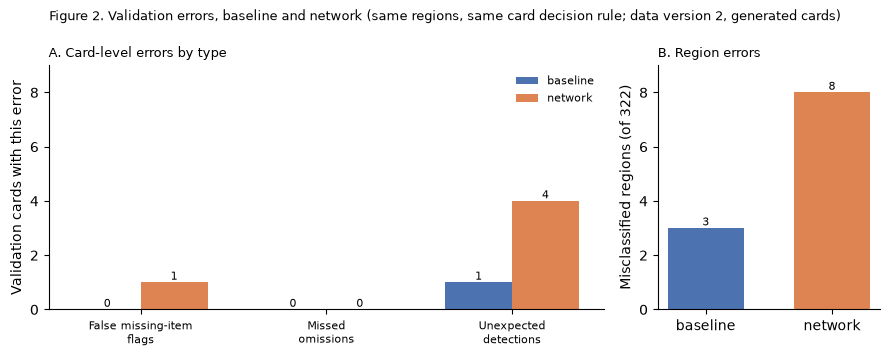

In [8]:
# Figure 2: card-level errors by type (distinct cards within each type) and region errors
TYPES = {"false_missing_flag": "False missing-item\nflags", "missed_omission": "Missed\nomissions",
         "unexpected_detection": "Unexpected\ndetections"}
COLOURS = {"baseline": "#4C72B0", "network": "#DD8452"}
cards_by_type = pd.DataFrame({m: [d.loc[d["outcome"] == t, "card_id"].nunique() for t in TYPES] for m, d in decisions.items()},
                             index=list(TYPES))
region_errors = pd.Series({m: int((scored["reference"] != scored[m]).sum()) for m in ["baseline", "network"]})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [3, 1.2]})
x = np.arange(len(TYPES))
for j, m in enumerate(["baseline", "network"]):
    bars = ax1.bar(x + (j - 0.5) * 0.36, cards_by_type[m], width=0.36, color=COLOURS[m], label=m)
    ax1.bar_label(bars, fontsize=8)
ax1.set_xticks(x, list(TYPES.values()), fontsize=8)
ax1.set_ylabel("Validation cards with this error")
ax1.set_title("A. Card-level errors by type", fontsize=9, loc="left")
ax1.legend(frameon=False, fontsize=8)
bars = ax2.bar(["baseline", "network"], region_errors, color=[COLOURS["baseline"], COLOURS["network"]], width=0.6)
ax2.bar_label(bars, fontsize=8)
ax2.set_ylabel(f"Misclassified regions (of {len(scored)})")
ax2.set_title("B. Region errors", fontsize=9, loc="left")
top = max(int(cards_by_type.to_numpy().max()), int(region_errors.max()), 1) + 1
for ax in (ax1, ax2):
    ax.set_ylim(0, top)
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Figure 2. Validation errors, baseline and network (same regions, same card decision rule; "
             "data version 2, generated cards)", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "tl_validation_errors.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2 caption.** *What it shows:* panel A counts, for each type of card-level error, the distinct validation cards with that error, for the baseline and the network. A card can have more than one type of error, so the bars should not be added together to give the number of cards with any error. Panel B counts misclassified regions among the 322 validation regions, all of which have a single reference label. *Why it matters:* the network made more region errors (8 against the baseline's 3) and more card-level errors (5 cards against 1). Six background objects or false regions were classified as phones: four became unexpected detections, and on the other two cards a phone was actually present, so no decision changed. One false region was classified as a laptop on a card where a laptop was present, also with no effect. The eighth error was the faint white hard hat that notebook 02's segmentation fitted poorly (overlap 0.41): the network called it "not a kit item", which gave its one false missing-item flag; the baseline recognised it. Both methods flagged all 43 omissions. *What it can't establish:* with only 43 omissions and 118 fully known cards, small differences provide limited evidence about performance on new cards. The prespecified rule determines which method proceeds. The cards are generated, not real kit photographs, and validation previously informed segmentation.

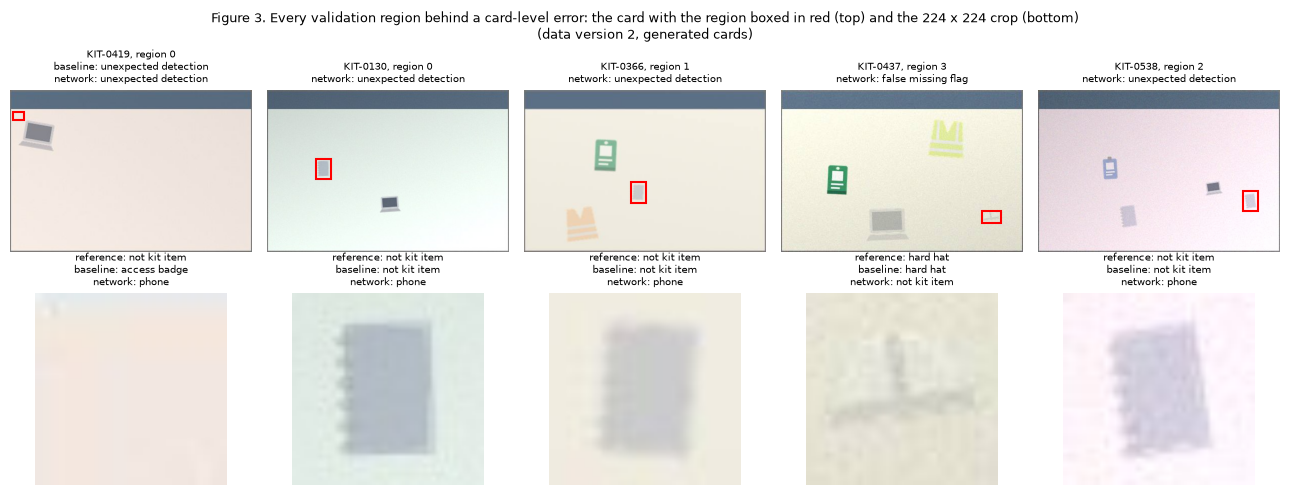

Background objects and false regions on validation, by how each method classified them:


method             baseline                                                 \
prediction     access_badge safety_vest hard_hat laptop phone not_kit_item   
object                                                                       
(false region)            2           0        0      0     0            0   
coffee_mug                0           0        0      1     0           21   
notebook                  0           0        0      0     0           30   
pen                       0           0        0      0     0           30   

method              network                                                 
prediction     access_badge safety_vest hard_hat laptop phone not_kit_item  
object                                                                      
(false region)            0           0        0      1     1            0  
coffee_mug                0           0        0      0     0           22  
notebook                  0           0        0      0     5           25  
pen                       0           0        0      0     0           30

In [9]:
# Figure 3: every region behind a card-level error: the original card and the crop supplied to the network
from matplotlib.patches import Rectangle
error_regions = []
for e in error_causes.itertuples():
    on_card = val[val["card_id"] == e.card_id]
    if e.outcome == "false_missing_flag":
        behind = on_card[(on_card["reference"] == e.item) & (on_card[e.method] != e.item)]
    else:
        behind = on_card[(on_card[e.method] == e.item) & (on_card["reference"] != e.item)]
    error_regions += [(e.card_id, int(r)) for r in behind["region"]]
error_regions = list(dict.fromkeys(error_regions))                  # each region once, in table order
assert 0 < len(error_regions) <= 8, "Figure 3 is laid out for up to 8 regions"
row_of = {(c, int(r)): k for k, (c, r) in enumerate(zip(regions["card_id"], regions["region"]))}
LABEL = lambda v: "no single reference" if pd.isna(v) else v.replace("_", " ")
fig, axes = plt.subplots(2, len(error_regions), figsize=(2.6 * len(error_regions), 5.0), squeeze=False)
for j, (card_id, region) in enumerate(error_regions):
    k = row_of[(card_id, region)]
    r, v = regions.loc[k], val[(val["card_id"] == card_id) & (val["region"] == region)].iloc[0]
    outcomes = error_causes[(error_causes["card_id"] == card_id)]
    outcomes = sorted({f"{m}: {o.replace('_', ' ')}" for m, o in zip(outcomes["method"], outcomes["outcome"])})
    axes[0, j].imshow(Image.open(KIT / "images" / files[card_id]).convert("RGB"))
    axes[0, j].add_patch(Rectangle((r["x0"] - 4, r["y0"] - 4), r["x1"] - r["x0"] + 8, r["y1"] - r["y0"] + 8,
                                   fill=False, edgecolor="red", linewidth=1.5))
    axes[0, j].set_title(f"{card_id}, region {region}\n" + "\n".join(outcomes), fontsize=7)
    axes[1, j].imshow(crops[k])
    axes[1, j].set_title(f"reference: {LABEL(v['reference'])}\nbaseline: {LABEL(v['baseline'])}\n"
                         f"network: {LABEL(v['network'])}", fontsize=7)
    for ax in axes[:, j]:
        ax.axis("off")
fig.suptitle("Figure 3. Every validation region behind a card-level error: the card with the region boxed in red (top) "
             "and the 224 x 224 crop (bottom)\n(data version 2, generated cards)", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "tl_error_regions_validation.png", dpi=150, bbox_inches="tight")
plt.show()

# Background objects by type: how each method classified them (validation)
background = val[val["label_group"].isin(["background_clean", "unmatched"])].merge(
    regions[["card_id", "region", "object"]], on=["card_id", "region"], how="left", validate="one_to_one")
background["object"] = background["object"].fillna("(false region)")
background_table = pd.concat({m: pd.crosstab(background["object"], background[m]).reindex(columns=CLASSES, fill_value=0)
                              for m in ["baseline", "network"]}, axis=1).astype(int)
background_table.columns.names = ["method", "prediction"]
background_table.to_csv(OUTPUT_DIR / "tl_background_predictions_validation.csv")
print("Background objects and false regions on validation, by how each method classified them:")
display(background_table)

**Figure 3 caption.** *What it shows:* every validation region behind a card-level error, five in all: the card with the region boxed (top), the crop the network classified (bottom), the reference label and both methods' predictions, and the resulting card-level error for each method. *Why it matters:* the network's errors come from three kinds of region. Three of the five are drawn notebooks, a background object, shown as pale grey rectangles with a spiral edge, which the network classified as phones; across validation it called 5 of the 30 notebooks phones (the other two were on cards where a phone was present, so no decision changed), while the baseline classified all 30 as "not a kit item" (table above). The fourth, on card KIT-0419, is a tiny false region at the card's top-left edge whose crop is almost plain paper; it is behind both methods' errors, as the baseline called it an access badge and the network a phone. The fifth is the faint white hard hat that segmentation fitted poorly: its crop is small and low-contrast, the network called it "not a kit item" and the baseline recognised it, so the network recognised 11 of the 12 faint white hard hats and the baseline 12 of 12. *What it can't establish:* why the network confused these regions. These are five regions on generated cards; they show where it failed here, not how often it would fail on new or real cards.

**Result of section C.** The network did not meet the prespecified criteria for replacing the baseline on validation. It met only the recall condition; it had more cards with a card-level error (5 against 1), lower missing-item precision, one false missing-item flag, more unexpected detections and fewer completely correct cards. The baseline therefore goes forward to robustness testing and the single test evaluation. This choice is saved in `tl_decision_rule_result.csv` and is not revisited; section D sets out what the network would have cost.

## D. What the network would have cost

The choice in section C is already fixed; this section only sets out, for the decision brief, what the network adds compared with the baseline. Model sizes and counts are read from the fitted models and saved files, not typed in.

**Timings** were measured on this computer's CPU (4 threads) and change from run to run, so they are saved separately (`tl_timings_this_run.csv`) and are not part of the reproducibility checks. The **prediction time** covers only the network's prediction step on crops already cut, resized and held in memory; cutting and resizing the crops (section A) is not included. Notebook 03 did not time the baseline, so no baseline timing is reported.

In [10]:
import joblib                                                       # reads notebook 03's saved baseline model

baseline_model = joblib.load(OUTPUT_DIR / "baseline_classifier.joblib")
scaler, logreg = baseline_model.named_steps["standardscaler"], baseline_model.named_steps["logisticregression"]
baseline_numbers = int(logreg.coef_.size + logreg.intercept_.size)
baseline_scaling = int(scaler.mean_.size + scaler.scale_.size)
network_all = int(sum(p.numel() for p in final_model.parameters()))
network_trained = int(sum(p.numel() for p in final_model.parameters() if p.requires_grad))
size_kb = lambda path: Path(path).stat().st_size / 1e3

costs = pd.DataFrame({
    "baseline": [
        f"{baseline_numbers} coefficients and intercepts ({logreg.coef_.shape[1]} features x {logreg.coef_.shape[0]} classes "
        f"+ {logreg.intercept_.size}), plus {baseline_scaling} scaling values",
        f"{size_kb(OUTPUT_DIR / 'baseline_classifier.joblib'):.1f} KB (baseline_classifier.joblib)",
        "the course stack only (NumPy, pandas, scikit-learn, OpenCV, Pillow)",
        "named colour and shape features, each with a coefficient per class (notebook 03)",
        "regularisation C, chosen by card-grouped cross-validation on training regions",
    ],
    "network": [
        f"{network_trained:,} trained parameters, of {network_all:,} used for every prediction",
        f"{size_kb(LAYERS_PATH) / 1e3:.1f} MB of trained layers (tl_trained_layers.pt) + "
        f"{size_kb(weights_file) / 1e3:.1f} MB of pretrained weights ({weights_file.name})",
        f"PyTorch {torch.__version__} and torchvision {torchvision.__version__}, plus a one-time download of the pretrained weights",
        "no direct interpretation through named colour and shape coefficients; this notebook examines behaviour "
        "through confusion tables and error examples",
        f"learning rate and number of epochs chosen on held-out training cards ({len(LR_GRID)} learning rates, epochs 1-{MAX_EPOCHS}); "
        "architecture, trained layers, augmentation, crop margin and batch size fixed in advance",
    ],
}, index=pd.Index(["learned numbers", "saved model files", "software beyond the course stack", "how its decisions can be read",
                   "settings chosen"], name="aspect"))
costs.insert(0, "data_version", DATA_VERSION)
costs.to_csv(OUTPUT_DIR / "tl_costs.csv")
with pd.option_context("display.max_colwidth", None):
    display(costs.drop(columns="data_version"))

timings = pd.DataFrame({
    "seconds": [round(search_seconds), round(final_seconds), round(predict_seconds, 1)],
    "what is timed": [f"settings search: {len(LR_GRID)} learning rates x {MAX_EPOCHS} epochs on the internal-fit cards, "
                      "scoring the hold-out after each epoch",
                      f"final model: {CHOSEN['epochs']} epochs on all {len(train_rows)} training regions",
                      f"prediction step only, {len(val)} validation regions (crops already in memory)"],
}, index=pd.Index(["settings search", "final training", "validation prediction"], name="step"))
timings.insert(0, "device", f"CPU, {torch.get_num_threads()} threads")
timings.to_csv(OUTPUT_DIR / "tl_timings_this_run.csv")
print("Timings for this run (they vary between runs and computers):")
with pd.option_context("display.max_colwidth", None):
    display(timings)

,baseline,network
aspect,,
learned numbers,"114 coefficients and intercepts (18 features x 6 classes + 6), plus 36 scaling values","653,446 trained parameters, of 1,524,006 used for every prediction"
saved model files,2.9 KB (baseline_classifier.joblib),2.6 MB of trained layers (tl_trained_layers.pt) + 10.3 MB of pretrained weights (mobilenet_v3_small-047dcff4.pth)
software beyond the course stack,"the course stack only (NumPy, pandas, scikit-learn, OpenCV, Pillow)","PyTorch 2.15.0 and torchvision 0.29.2, plus a one-time download of the pretrained weights"
how its decisions can be read,"named colour and shape features, each with a coefficient per class (notebook 03)",no direct interpretation through named colour and shape coefficients; this notebook examines behaviour through confusion tables and error examples
settings chosen,"regularisation C, chosen by card-grouped cross-validation on training regions","learning rate and number of epochs chosen on held-out training cards (2 learning rates, epochs 1-10); architecture, trained layers, augmentation, crop margin and batch size fixed in advance"


Timings for this run (they vary between runs and computers):


,device,seconds,what is timed
step,,,
settings search,"CPU, 4 threads",353.0,"settings search: 2 learning rates x 10 epochs on the internal-fit cards, scoring the hold-out after each epoch"
final training,"CPU, 4 threads",38.0,final model: 2 epochs on all 916 training regions
validation prediction,"CPU, 4 threads",5.1,"prediction step only, 322 validation regions (crops already in memory)"


## E. Checks

In [11]:
dev_card_ids = set(manifest.loc[manifest["split"].isin(DEV_SPLITS), "card_id"])
test_card_ids = set(manifest.loc[~manifest["split"].isin(DEV_SPLITS), "card_id"])
cropped_cards = set(regions["card_id"])                             # crops were cut only for these cards
fit_cards = set(data.loc[fit_rows, "card_id"])
hold_cards = set(data.loc[hold_rows, "card_id"])
saved_rule = pd.read_csv(RULE_PATH, index_col=0, dtype=str, keep_default_na=False)
error_keys = {m: set(map(tuple, d.loc[d["outcome"].isin(ERRORS), ["card_id", "item"]].to_numpy())) for m, d in decisions.items()}
listed_keys = {m: set(map(tuple, error_causes.loc[error_causes["method"] == m, ["card_id", "item"]].to_numpy())) for m in decisions}
unresolved = int((error_causes["causes"] == "unresolved").sum())

checks = pd.Series({
    "Pretrained weights file has the expected checksum": sha(weights_file) == WEIGHTS_SHA256,
    "Regions and training rows match notebook 03's fingerprints":
        sha(OUTPUT_DIR / "regions_dev.csv") == baseline_settings["regions_dev_sha256"]
        and sha(OUTPUT_DIR / "classifier_training_regions.csv") == baseline_settings["training_regions_sha256"],
    "Crops were cut only from development cards (no test card)":
        cropped_cards <= dev_card_ids and not (cropped_cards & test_card_ids),
    "One square 224 x 224 crop per region": crops.shape == (len(regions), CROP_SIZE, CROP_SIZE, 3),
    "Internal hold-out is split by card": fit_cards.isdisjoint(hold_cards),
    "Both sides of the internal hold-out contain every class":
        all(set(data.loc[rows, "reference"]) == set(CLASSES) for rows in [fit_rows, hold_rows]),
    "Training and settings choice used training cards only":
        (data.loc[np.concatenate([fit_rows, hold_rows, train_rows]), "split"] == "train").all()
        and (fit_cards | hold_cards) <= set(train_cards),
    "Final model trained on exactly notebook 03's 916 training regions": len(train_rows) == 916
        and set(map(tuple, data.loc[train_rows, key].to_numpy())) == set(map(tuple, training_regions[key].to_numpy())),
    "Saved trained layers rebuild the model exactly": RECONSTRUCTED,
    "Every validation region has a network prediction": len(val) == n_val and val["network"].isin(CLASSES).all(),
    "The decision rule reproduces notebook 03's baseline decisions": RULE_REPRODUCED,
    "The summary reproduces notebook 03's baseline summary": SUMMARY_REPRODUCED,
    "Baseline present-item recognition matches notebook 03": RECOGNITION_REPRODUCED,
    "Every validation card has exactly one decision for each item, for both methods":
        all(len(d) == len(val_cards) * len(ITEMS) and not d.duplicated(["card_id", "item"]).any()
            and set(zip(d["card_id"], d["item"])) == {(c, i) for c in val_cards["card_id"] for i in ITEMS}
            for d in decisions.values()),
    "Omission counts match the manifest, for both methods":
        all(int(d["outcome"].isin(["correct_missing_flag", "missed_omission"]).sum())
            == int(val_cards[[f"omitted_{i}" for i in ITEMS]].to_numpy().sum()) for d in decisions.values()),
    "Unknown expectations are never scored, for both methods":
        all((d.loc[~d["known"], "outcome"] == "needs_review").all() for d in decisions.values()),
    "Every erroneous card-item decision appears in the error table, for both methods":
        all(error_keys[m] == listed_keys[m] for m in decisions) and len(error_causes) == sum(map(len, error_keys.values())),
    "The decision table matches the saved result": saved_rule.equals(rule.astype(str)),
}, name="passed")
checks.index.name = "check"
checks.to_csv(OUTPUT_DIR / "checks_04.csv")
display(checks.to_frame())
print(f"Erroneous card-item decisions with an unresolved cause: {unresolved}")
assert checks.all(), "A check failed"

,passed
check,
Pretrained weights file has the expected checksum,True
Regions and training rows match notebook 03's fingerprints,True
Crops were cut only from development cards (no test card),True
One square 224 x 224 crop per region,True
Internal hold-out is split by card,True
Both sides of the internal hold-out contain every class,True
Training and settings choice used training cards only,True
Final model trained on exactly notebook 03's 916 training regions,True
Saved trained layers rebuild the model exactly,True


Erroneous card-item decisions with an unresolved cause: 0


## Summary

**Question:** Does a small pretrained neural network, trained using the same frozen regions, classify regions and flag missing items better than notebook 03's colour-and-shape baseline, and is any gain worth the added complexity?

**Data version:** 2. The same frozen regions from notebook 02 and the same 916 training regions as notebook 03; training settings were chosen on 69 held-out training cards, and validation was used once, for the comparison. No test image was opened.

**Method:** Each region was cut from its card as a square crop and classified by MobileNetV3-Small, pretrained on ImageNet; only its last feature block and its classifier head (with a new six-class output) were trained, with light augmentation and balanced class weights. The search covered one architecture and one training seed, two learning rates and epochs 1–10, scored by region macro F1 on the held-out training cards. The network's region predictions went through notebook 03's card decision rule, copied unchanged and shown to reproduce the baseline's saved decisions exactly, and the two methods were compared with a decision rule fixed before any network result was seen.

**Key findings:**

1. **The network learned the training crops almost at once.** Both learning rates classified all 183 held-out training regions correctly from the second epoch; the tie-break rule fixed in advance chose a learning rate of 0.0003 and 2 epochs.
2. **On validation it made more errors than the baseline.** It classified 314 of 322 regions correctly (region macro F1 0.970) against the baseline's 319 (0.992). Both methods flagged all 43 omissions, but the network had 5 cards with a card-level error against the baseline's 1: one false missing-item flag and four unexpected detections, against the baseline's one unexpected detection.
3. **Its card-level errors involved three kinds of region.** It classified 5 of the 30 drawn notebooks on validation as phones (three became unexpected detections; the other two were on cards where a phone was present), a tiny false region at a card edge as a phone (the same region behind the baseline's error), and the faint white hard hat that segmentation fitted poorly as "not a kit item", which gave its false flag. It recognised 11 of the 12 faint white hard hats; the baseline recognised all 12.
4. **The network did not meet the prespecified criteria for replacing the baseline on validation.** It met only the recall condition, so the baseline goes forward to robustness testing and the single test evaluation (`tl_decision_rule_result.csv`).
5. **It would add cost.** The network trains 653,446 parameters and uses 1,524,006 for every prediction, against the baseline's 114 coefficients; its saved files take 2.6 MB plus the 10.3 MB pretrained weights, against 2.9 KB; it needs PyTorch, torchvision and a one-time weights download; and its decisions cannot be read through named features.

**What this means:** on these generated cards, the extra complexity of the network did not bring better card decisions on validation. This supports carrying the baseline forward; whether the baseline is good enough is judged later, by the robustness tests and the single test evaluation. As before, a coordinator checks every suggested missing item.

**Limitations:** One architecture and training seed were tried, with two learning rates and epochs 1–10; another design or seed could behave differently. Validation is small (43 omissions, 118 cards with all expectations known), so small differences provide limited evidence about performance on new cards, and it previously informed segmentation. The cards are computer-generated, not real kit photographs. The network's class probabilities are uncalibrated and were not used. Timings depend on the computer. Deterministic training supports reproducibility in the tested environment; it doesn't guarantee the same result after changes to code, inputs or packages.

**To reproduce:** from this folder, with the project environment (`.venv`, Python 3.14, PyTorch 2.15.0, torchvision 0.29.2) and the pretrained weights downloaded once as described in the README, run notebooks 02 and 03 first (their saved regions, training rows and baseline results are inputs here), then choose Restart and Run All (about 7 minutes on a CPU). Tables are saved to `../outputs/` and figures to `../figures/`. A rerun checks that the decision table matches the committed `tl_decision_rule_result.csv`.